<a href="https://colab.research.google.com/github/ibrahimhalil63aslan/industrial-predictive-maintenance/blob/main/industrial_water_pump_predictive_maintenance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ===============================================================
# Water Pump Sensor Data - Predictive Maintenance & Anomaly Detection
# ===============================================================
# This notebook implements an end-to-end pipeline for industrial water pump
# sensor data, covering exploratory data analysis, time-series preprocessing,
# rolling feature engineering, and unsupervised anomaly detection using
# Isolation Forest.
# ===============================================================

In [ ]:
import pandas as pd
import numpy as np

# CSV dosyasını Pandas DataFrame'ine aktarıyoruz
df = pd.read_csv('sensor.csv')
print("Veri seti başarıyla yüklendi!")
print(f"Veri boyutu (Satır, Sütun): {df.shape}")

Veri seti başarıyla yüklendi!
Veri boyutu (Satır, Sütun): (59771, 55)


In [ ]:
# Veri setinin ilk 5 satırını görüntüleyelim
print("İlk 5 satır:")
display(df.head())

# Veri setinin genel bilgilerine bakalım
print("\nVeri seti bilgisi:")
df.info()

# Eksik değerleri kontrol edelim
print("\nEksik değer sayıları:")
display(df.isnull().sum())

İlk 5 satır:


,Unnamed: 0,timestamp,sensor_00,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05,sensor_06,sensor_07,...,sensor_43,sensor_44,sensor_45,sensor_46,sensor_47,sensor_48,sensor_49,sensor_50,sensor_51,machine_status
0,0,2018-04-01 00:00:00,2.465394,47.09201,53.2118,46.310760,634.3750,76.45975,13.41146,16.13136,...,41.92708,39.641200,65.68287,50.92593,38.194440,157.9861,67.70834,243.0556,201.3889,NORMAL
1,1,2018-04-01 00:01:00,2.465394,47.09201,53.2118,46.310760,634.3750,76.45975,13.41146,16.13136,...,41.92708,39.641200,65.68287,50.92593,38.194440,157.9861,67.70834,243.0556,201.3889,NORMAL
2,2,2018-04-01 00:02:00,2.444734,47.35243,53.2118,46.397570,638.8889,73.54598,13.32465,16.03733,...,41.66666,39.351852,65.39352,51.21528,38.194443,155.9606,67.12963,241.3194,203.7037,NORMAL
3,3,2018-04-01 00:03:00,2.460474,47.09201,53.1684,46.397568,628.1250,76.98898,13.31742,16.24711,...,40.88541,39.062500,64.81481,51.21528,38.194440,155.9606,66.84028,240.4514,203.1250,NORMAL
4,4,2018-04-01 00:04:00,2.445718,47.13541,53.2118,46.397568,636.4583,76.58897,13.35359,16.21094,...,41.40625,38.773150,65.10416,51.79398,38.773150,158.2755,66.55093,242.1875,201.3889,NORMAL



Veri seti bilgisi:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59771 entries, 0 to 59770
Data columns (total 55 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      59771 non-null  int64  
 1   timestamp       59771 non-null  object 
 2   sensor_00       55744 non-null  float64
 3   sensor_01       59707 non-null  float64
 4   sensor_02       59762 non-null  float64
 5   sensor_03       59762 non-null  float64
 6   sensor_04       59762 non-null  float64
 7   sensor_05       59762 non-null  float64
 8   sensor_06       59525 non-null  float64
 9   sensor_07       59567 non-null  float64
 10  sensor_08       59061 non-null  float64
 11  sensor_09       59762 non-null  float64
 12  sensor_10       59762 non-null  float64
 13  sensor_11       59762 non-null  float64
 14  sensor_12       59762 non-null  float64
 15  sensor_13       59762 non-null  float64
 16  sensor_14       59761 non-null  float64
 17  sensor_15  

,0
Unnamed: 0,0
timestamp,0
sensor_00,4027
sensor_01,64
sensor_02,9
sensor_03,9
sensor_04,9
sensor_05,9
sensor_06,246
sensor_07,204


In [ ]:
# timestamp sütununu datetime formatına çevirelim
df['timestamp'] = pd.to_datetime(df['timestamp'])

# Dönüşümün doğru yapılıp yapılmadığını ve yeni veri tiplerini kontrol edelim
print("--- ZAMAN SERİSİ DÖNÜŞÜMÜ SONRASI ---")
print(df[['timestamp']].dtypes)

# İsteğe bağlı: Zaman damgasını DataFrame'in index'i yapabiliriz (Zaman serisi grafikleri için çok pratiktir)
# df.set_index('timestamp', inplace=True)
# print("\nIndex artık timestamp oldu. İlk 3 satır:")
# display(df.head(3))

--- ZAMAN SERİSİ DÖNÜŞÜMÜ SONRASI ---
timestamp    datetime64[ns]
dtype: object


In [ ]:
# 1. Sayısal sensör sütunlarının istatistiksel özetini görelim
print("--- TANIMLAYICI İSTATİSTİKLER (DESCRIBE) ---")
display(df.describe())

# 2. Eksik (Null/NaN) değerlerin güncel durumunu tekrar kontrol edelim
print("\n--- EKSİK DEĞER SAYILARI ---")
display(df.isnull().sum())

--- TANIMLAYICI İSTATİSTİKLER (DESCRIBE) ---


,Unnamed: 0,timestamp,sensor_00,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05,sensor_06,sensor_07,...,sensor_42,sensor_43,sensor_44,sensor_45,sensor_46,sensor_47,sensor_48,sensor_49,sensor_50,sensor_51
count,59771.000000,59771,55744.000000,59707.000000,59762.000000,59762.000000,59762.000000,59762.000000,59525.000000,59567.000000,...,59761.000000,59761.000000,59761.000000,59761.000000,59761.000000,59761.000000,59761.000000,59761.000000,59761.000000,59761.00000
mean,29885.000000,2018-04-21 18:05:00,2.390611,47.565644,51.100375,43.544630,587.627009,72.827904,12.694584,15.512482,...,36.325615,43.792764,41.140256,43.402321,44.715644,41.923132,123.350143,56.002415,196.246817,185.74010
min,0.000000,2018-04-01 00:00:00,0.000000,22.439240,36.545140,33.289930,2.873264,0.000000,0.014468,0.000000,...,23.437500,27.604166,26.620370,26.331020,27.777779,27.777779,28.645830,28.067130,31.539350,30.67130
25%,14942.500000,2018-04-11 09:02:30,2.406366,46.223960,50.607635,42.317707,625.347200,72.478002,13.172740,16.124130,...,31.770830,39.062500,36.168980,37.326389,38.773150,37.905090,81.597220,46.875000,181.423600,179.10880
50%,29885.000000,2018-04-21 18:05:00,2.451620,47.699650,51.909720,44.053818,631.365700,77.372980,13.346350,16.167530,...,35.156250,42.187500,40.219910,41.087960,42.245370,40.798611,114.583300,52.083332,204.282400,195.02310
75%,44827.500000,2018-05-02 03:07:30,2.456539,49.131940,52.951390,45.312500,636.574000,82.197400,13.563370,16.341150,...,38.281250,45.833330,43.981480,45.428242,46.585650,44.560180,160.300900,59.606480,227.719900,210.93750
max,59770.000000,2018-05-12 12:10:00,2.518518,55.772570,55.598960,48.046880,671.990700,99.999880,18.221930,21.274600,...,374.218800,408.593700,221.064800,220.196800,320.891200,196.759300,502.314800,323.206000,483.506900,466.14580
std,17254.545807,NaN,0.248393,2.802473,3.398904,2.476534,146.208416,20.710756,2.735201,3.122776,...,15.212767,15.811072,8.400228,12.160597,14.901623,8.025318,55.650583,16.226816,57.272302,50.70301



--- EKSİK DEĞER SAYILARI ---


,0
Unnamed: 0,0
timestamp,0
sensor_00,4027
sensor_01,64
sensor_02,9
sensor_03,9
sensor_04,9
sensor_05,9
sensor_06,246
sensor_07,204


In [ ]:
# 1. Tamamen boş veya analize engel olacak gereksiz sütunları (örn: Unnamed: 0) kaldıralım
if 'Unnamed: 0' in df.columns:
    df.drop(columns=['Unnamed: 0'], inplace=True)

# 2. sensor_15 sütunu tamamen boş olduğu için veri setinden çıkarabiliriz
if 'sensor_15' in df.columns:
    df.drop(columns=['sensor_15'], inplace=True)

# 3. Diğer sensörlerdeki eksik değerleri zaman serisi yöntemiyle (ileri doldurma - ffill) dolduralım
df.ffill(inplace=True)

# 4. Kalan eksik değer kontrolü yapalım
print("--- TEMİZLİK SONRASI EKSİK DEĞER SAYILARI ---")
display(df.isnull().sum().max()) # Maksimum eksik değer 0 olmalı!

--- TEMİZLİK SONRASI EKSİK DEĞER SAYILARI ---


0

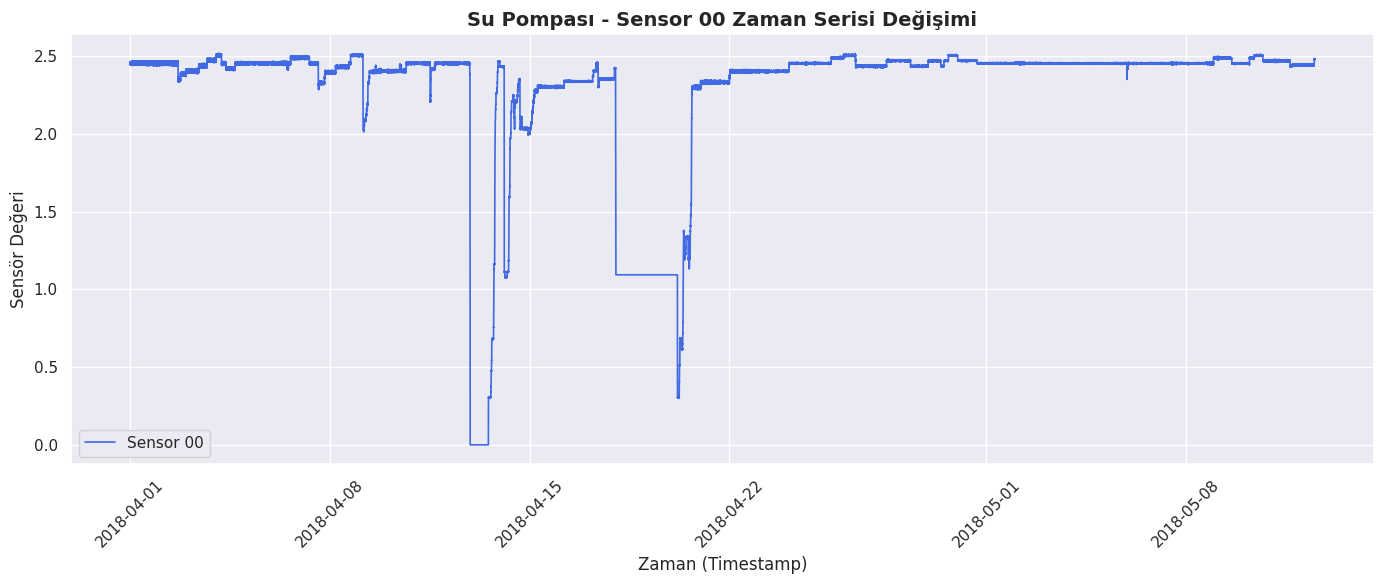

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Grafik stilini ayarlayalım
sns.set_theme(style="darkgrid")
plt.figure(figsize=(14, 6))

# Örnek olarak ilk sensörümüzün (sensor_00) zaman içindeki değişimini çizdirelim
plt.plot(df['timestamp'], df['sensor_00'], color='royalblue', linewidth=1.2, label='Sensor 00')

# Grafik başlıkları ve etiketler
plt.title('Su Pompası - Sensor 00 Zaman Serisi Değişimi', fontsize=14, fontweight='bold')
plt.xlabel('Zaman (Timestamp)', fontsize=12)
plt.ylabel('Sensör Değeri', fontsize=12)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

# Grafiği gösterelim
plt.show()

In [ ]:
# 1. machine_status sütununda hangi durumlar var ve kaçar tane bakalım
print("--- MAKİNE DURUMU DAĞILIMI ---")
print(df['machine_status'].value_counts())

# 2. Sensor_00 değerinin düştüğü o kritik tarih aralığını (Örn: 12-16 Nisan) filtreleyelim
anomaly_period = df[(df['timestamp'] >= '2018-04-12') & (df['timestamp'] <= '2018-04-16')]

print("\n--- ANOMALİ DÖNEMİNDEKİ MAKİNE DURUMLARI ---")
print(anomaly_period['machine_status'].value_counts())

--- MAKİNE DURUMU DAĞILIMI ---
machine_status
NORMAL        55715
RECOVERING     4054
BROKEN            2
Name: count, dtype: int64

--- ANOMALİ DÖNEMİNDEKİ MAKİNE DURUMLARI ---
machine_status
NORMAL        4816
RECOVERING     944
BROKEN           1
Name: count, dtype: int64


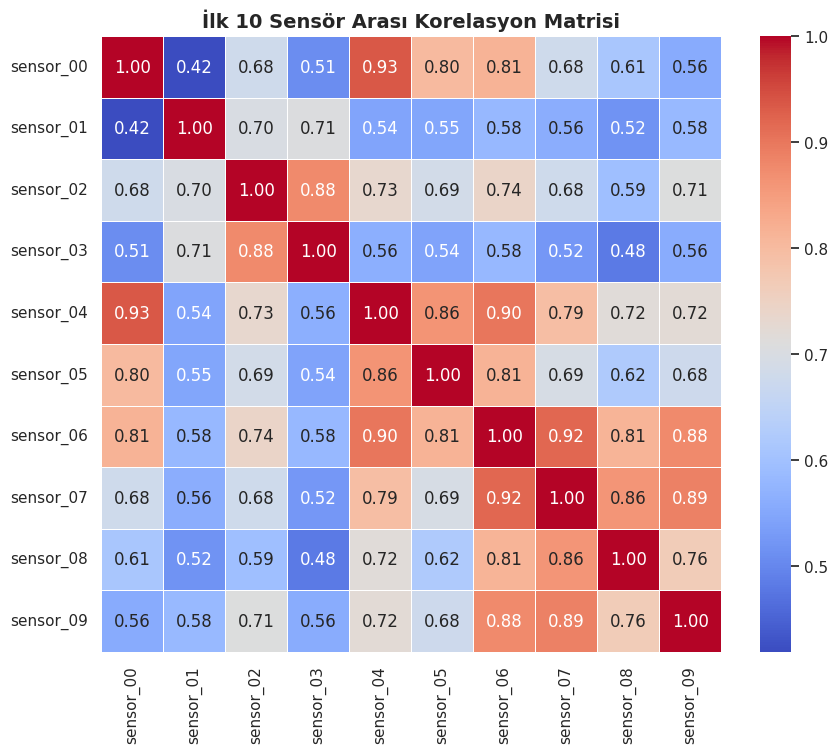

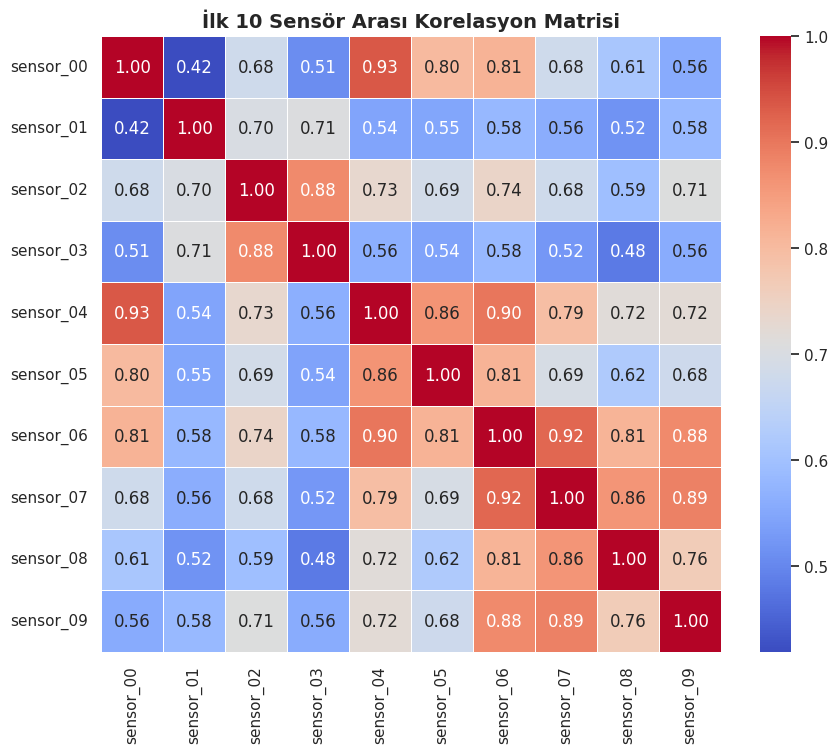

In [ ]:
# 1. Sayısal sensör sütunları arasındaki korelasyon matrisini hesaplayalım
# (Çok fazla sütun olduğu için ilk 10 sensörü örnek olarak alabiliriz)
sensor_cols = [col for col in df.columns if 'sensor_' in col][:10]
corr_matrix = df[sensor_cols].corr()

# 2. Korelasyon matrisini görselleştirelim
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('İlk 10 Sensör Arası Korelasyon Matrisi', fontsize=14, fontweight='bold')
plt.show()# 1. Sayısal sensör sütunları arasındaki korelasyon matrisini hesaplayalım
# (Çok fazla sütun olduğu için ilk 10 sensörü örnek olarak alabiliriz)
sensor_cols = [col for col in df.columns if 'sensor_' in col][:10]
corr_matrix = df[sensor_cols].corr()

# 2. Korelasyon matrisini görselleştirelim
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('İlk 10 Sensör Arası Korelasyon Matrisi', fontsize=14, fontweight='bold')
plt.show()

In [ ]:
# machine_status sütunundaki metinsel durumları (NORMAL, BROKEN vb.) makine öğrenmesi modellerinin anlayacağı sayısal değerlere çevirelim
# Örneğin: NORMAL -> 0, RECOVERING -> 1, BROKEN -> 2 yapabiliriz veya arıza durumunu 1, diğerlerini 0 yapabiliriz (Binary classification için).

# Basit bir yaklaşım olarak arıza (BROKEN) durumunu 1, diğer tüm durumları 0 yapalım (Binary Anomali Tespiti):
df['target'] = df['machine_status'].apply(lambda x: 1 if x == 'BROKEN' else 0)

# Yeni hedef değişkenimizin dağılımına bakalım
print("--- HEDEF DEĞİŞKEN (TARGET) DAĞILIMI ---")
print(df['target'].value_counts())

--- HEDEF DEĞİŞKEN (TARGET) DAĞILIMI ---
target
0    59769
1        2
Name: count, dtype: int64


In [ ]:
# 1. Örnek olarak sensor_00 üzerinde 60 adımlık (örneğin 60 dakikalık) hareketli ortalama ve standart sapma türetelim
df['sensor_00_rolling_mean'] = df['sensor_00'].rolling(window=60, min_periods=1).mean()
df['sensor_00_rolling_std'] = df['sensor_00'].rolling(window=60, min_periods=1).std().fillna(0)

# 2. Ürettiğimiz yeni özellikleri ve veri setinin güncel boyutunu kontrol edelim
print("--- ÖZNİTELİK MÜHENDİSLİĞİ SONRASI ---")
print(f"Toplam Sütun Sayısı: {df.shape[1]}")
display(df[['timestamp', 'sensor_00', 'sensor_00_rolling_mean', 'sensor_00_rolling_std']].tail())

--- ÖZNİTELİK MÜHENDİSLİĞİ SONRASI ---
Toplam Sütun Sayısı: 56


,timestamp,sensor_00,sensor_00_rolling_mean,sensor_00_rolling_std
59766,2018-05-12 12:06:00,2.483102,2.459343,0.017899
59767,2018-05-12 12:07:00,2.478183,2.459884,0.017971
59768,2018-05-12 12:08:00,2.481134,2.460557,0.017999
59769,2018-05-12 12:09:00,2.478183,2.461032,0.018083
59770,2018-05-12 12:10:00,2.479167,2.461737,0.017949


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# 1. Özellikler (X) ve Hedef Değişkeni (y) belirleyelim
# Zaman damgası ve metinsel durum sütunlarını model dışı bırakıyoruz
drop_cols = ['timestamp', 'machine_status', 'target']
X = df.drop(columns=[col for col in drop_cols if col in df.columns])
y = df['target']

# 2. Veriyi Eğitim ve Test olarak bölelim (Zaman serisi mantığına uygun olarak karıştırmadan - shuffle=False)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

print(f"Eğitim seti boyutu: {X_train.shape}")
print(f"Test seti boyutu: {X_test.shape}")

Eğitim seti boyutu: (47816, 53)
Test seti boyutu: (11955, 53)


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# 1. Random Forest modelini tanımlayalım
# Sınıfların dengesizliğini modelin dikkate alması için class_weight='balanced' parametresini kullanıyoruz
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')

# 2. Modeli eğitim setiyle (X_train, y_train) eğitelim
print("Model eğitiliyor, lütfen bekleyin...")
rf_model.fit(X_train, y_train)
print("Model eğitimi tamamlandı!")

# 3. Test seti üzerinde tahminler yapalım
y_pred = rf_model.predict(X_test)

# 4. Sonuçları değerlendirelim
print("\n--- KARIŞIKLIK MATRİSİ (CONFUSION MATRIX) ---")
print(confusion_matrix(y_test, y_pred))

print("\n--- SINIFLANDIRMA RAPORU ---")
print(classification_report(y_test, y_pred, zero_division=0))

Model eğitiliyor, lütfen bekleyin...
Model eğitimi tamamlandı!

--- KARIŞIKLIK MATRİSİ (CONFUSION MATRIX) ---
[[11955]]

--- SINIFLANDIRMA RAPORU ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     11955

    accuracy                           1.00     11955
   macro avg       1.00      1.00      1.00     11955
weighted avg       1.00      1.00      1.00     11955



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


In [ ]:
print(f"Eğitim setindeki arıza (1) sayısı: {y_train.sum()}")
print(f"Test setindeki arıza (1) sayısı: {y_test.sum()}")

Eğitim setindeki arıza (1) sayısı: 2
Test setindeki arıza (1) sayısı: 0


In [ ]:
from sklearn.ensemble import IsolationForest

# 1. Isolation Forest modelini kuralım
# contamination parametresi, veri setindeki tahmini anomali oranını belirtir (Çok düşük tutuyoruz, örn: %0.1)
iso_model = IsolationForest(contamination=0.001, random_state=42)

# 2. Modeli eğitelim ve tahmin alalım (Gözetimsiz olduğu için sadece X özelliklerini veriyoruz)
# Isolation Forest normal veriye 1, anomaliye -1 atar.
predictions = iso_model.fit_predict(X)

# 3. Sonuçları okunabilir hale getirelim: -1 (anomali) -> 1 yapalım, 1 (normal) -> 0 yapalım
df['anomaly_pred'] = [1 if x == -1 else 0 for x in predictions]

# Gerçek arızalarımızla modelin yakaladığı anomalileri karşılaştıralım
print("--- MODELİN YAKALADIĞI ANOMALİ DAĞILIMI ---")
print(df['anomaly_pred'].value_counts())

# Gerçek arıza (target == 1) ile modelin anomali dediği (anomaly_pred == 1) durumların örtüşmesine bakalım
print("\nGerçek Arızalar ile Model Tahminlerinin Kesişimi:")
print(df[(df['target'] == 1) | (df['anomaly_pred'] == 1)][['timestamp', 'sensor_00', 'target', 'anomaly_pred']].head(10))

--- MODELİN YAKALADIĞI ANOMALİ DAĞILIMI ---
anomaly_pred
0    59711
1       60
Name: count, dtype: int64

Gerçek Arızalar ile Model Tahminlerinin Kesişimi:
                timestamp  sensor_00  target  anomaly_pred
17155 2018-04-12 21:55:00   0.000000       1             0
18298 2018-04-13 16:58:00   0.684722       0             1
18299 2018-04-13 16:59:00   0.680787       0             1
18300 2018-04-13 17:00:00   0.677836       0             1
18301 2018-04-13 17:01:00   0.677836       0             1
18302 2018-04-13 17:02:00   0.684722       0             1
18303 2018-04-13 17:03:00   0.679803       0             1
18304 2018-04-13 17:04:00   0.677836       0             1
18305 2018-04-13 17:05:00   0.680787       0             1
18306 2018-04-13 17:06:00   0.683738       0             1


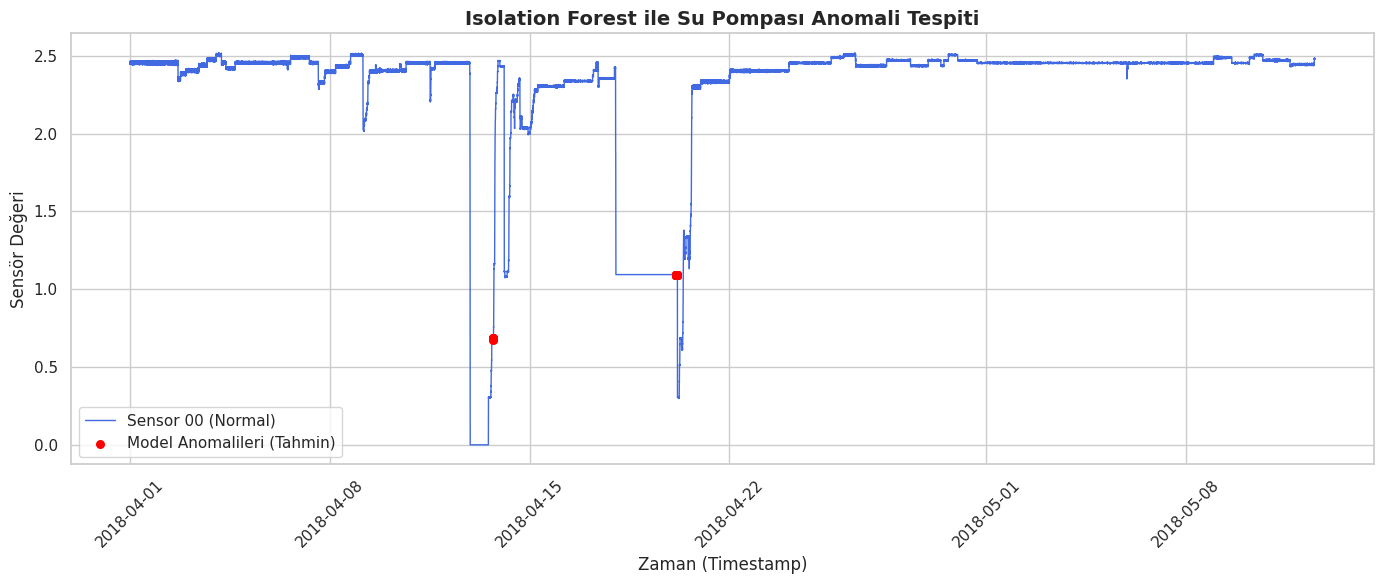

In [ ]:
# 1. Grafik boyutunu ayarlayalım
plt.figure(figsize=(14, 6))

# 2. Normal sensör değerlerini çizdirelim
plt.plot(df['timestamp'], df['sensor_00'], color='royalblue', linewidth=1, label='Sensor 00 (Normal)')

# 3. Modelin anomali olarak tespit ettiği noktaları (anomaly_pred == 1) kırmızı noktalarla işaretleyelim
anomalies = df[df['anomaly_pred'] == 1]
plt.scatter(anomalies['timestamp'], anomalies['sensor_00'], color='red', s=30, label='Model Anomalileri (Tahmin)', zorder=5)

# 4. Grafik başlıkları ve düzenlemeler
plt.title('Isolation Forest ile Su Pompası Anomali Tespiti', fontsize=14, fontweight='bold')
plt.xlabel('Zaman (Timestamp)', fontsize=12)
plt.ylabel('Sensör Değeri', fontsize=12)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

# Grafiği gösterelim
plt.show()